# LLM and Fake News

### Dataset setting and data preprocessing

In [1]:
import pandas as pd
import kagglehub
import os

# Reference to the downloaded path 
path = kagglehub.dataset_download("doanquanvietnamca/liar-dataset")


# Load train set and test set + header definition
col_names = ['id', 'label', 'statement', 'subject', 'speaker', 'job', 'state', 'party', 
             'barely_true', 'false', 'half_true', 'mostly_true', 'pants_on_fire', 'context']

df_train = pd.read_csv(os.path.join(path, 'train.tsv'), sep='\t', names=col_names, header=None)
df_test = pd.read_csv(os.path.join(path, 'test.tsv'), sep='\t', names=col_names, header=None)

# Select 'statement' column and 'label' column
df_train = df_train[['statement', 'label']].dropna() # train set
df_test = df_test[['statement', 'label']].dropna() # test set

c:\Users\Utente\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# 6 class mapping (false, half-true, mostly-true, true, barely-true, pants-on-fire):
# 'true', 'mostly_true' -> 1 (true)
#  else -> 0 (false)
def map_label(label):
    if label in ['true', 'mostly-true']:
        return 1 
    else:
        return 0  

df_train['binary_label'] = df_train['label'].apply(map_label)
df_test['binary_label'] = df_test['label'].apply(map_label)

print(df_train[['label', 'binary_label']].head())

         label  binary_label
0        false             0
1    half-true             0
2  mostly-true             1
3        false             0
4    half-true             0


### Utility Functions

In [ ]:
import json
import ollama
from tqdm import tqdm

# Utility functions to build prompts: 

# Plain text prompt
def generate_prompt_plaintext(news_item):
    return f"Tell me whether this news is true or false. Answer using only the word 'True' or 'False': \n\n{news_item}"

# Markdown prompt
def generate_prompt_markdown(news_item):
    return f"""### Instruction:
Evaluate the truthfullness of the given text. Answer strictly choosing only between the options 'True' or 'False'.

### News to analyze:
> {news_item}

### Answer:
"""
# JSON prompt
def generate_prompt_json(news_item):
    structure = {
        "task": "Fake news detection",
        "instruction": "Analyze the news in the 'text' field and write your answer in the field 'allowed_answer' choosing between 'True' or 'False'.",
        "news": {
            "text": news_item
        },
        "allowed_answer": ["True", "False"]
    }
    return json.dumps(structure, ensure_ascii=False)


# utility function to query ollama
def ask_ollama(prompt, model="llama3.1"):
    try:
        response = ollama.chat(
            model = model,
            messages = [{'role': 'user', 'content': prompt}],
            options = {'temperature': 0.0}
        )
        return response['message']['content'].strip()
    except Exception as e:
        return f"ERRORE: {str(e)}"

# Test dataset samples selection
df_test_sample = df_test.sample(n=200, random_state=42).copy()


### SVM

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.calibration import CalibratedClassifierCV

# Preparation and vectorialization of the raw text 
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(df_train['statement'])

# Vectorialization of the 200 rows sample (the same for the other models)
X_test_sample_raw = df_test_sample['statement']
X_test_tfidf = vectorizer.transform(X_test_sample_raw)

# SVM training and fitting
svm_model = LinearSVC(random_state=42, dual='auto', class_weight='balanced')
svm_model.fit(X_train_tfidf, df_train['binary_label'])

# Predictions and decision function
decision_scores = svm_model.decision_function(X_test_tfidf)
y_pred_svm = svm_model.predict(X_test_tfidf)

# Metrics computation
y_true = df_test_sample['binary_label']
acc_svm = accuracy_score(y_true, y_pred_svm)
prec_svm, rec_svm, f1_svm, _ = precision_recall_fscore_support(y_true, y_pred_svm, average='binary')

print("--- SVM (raw text) ---")
print(f"Accuracy:  {acc_svm:.4f}")
print(f"Precision: {prec_svm:.4f}")
print(f"Recall:    {rec_svm:.4f}")
print(f"F1-Score:  {f1_svm:.4f}")

svm_metrics = [
    {'Model': 'SVM (Baseline)', 'Format': fmt, 'Accuracy': acc_svm, 'Precision': prec_svm, 'Recall': rec_svm, 'F1-Score': f1_svm}
    for fmt in ['Plaintext', 'Markdown', 'JSON']
]

--- SVM (raw text) ---
Accuracy:  0.6400
Precision: 0.5057
Recall:    0.6027
F1-Score:  0.5500


### Linear Regression

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Preparation and vectorialization of the raw text 
vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = vectorizer.fit_transform(df_train['statement'])

# Vectorialization of the 200 rows sample (the same for the other models)
X_test_sample_raw = df_test_sample['statement']
X_test_tfidf = vectorizer.transform(X_test_sample_raw)

# Logistic Regression training and fitting
lr_model = LogisticRegression(random_state=42, class_weight='balanced')
lr_model.fit(X_train_tfidf, df_train['binary_label'])

# Predictions and decision function
probabilities = lr_model.predict_proba(X_test_tfidf)
y_pred_lr = lr_model.predict(X_test_tfidf)

# Metrics computation
y_true = df_test_sample['binary_label']
acc_lr = accuracy_score(y_true, y_pred_svm)
prec_lr, rec_lr, f1_lr, _ = precision_recall_fscore_support(y_true, y_pred_lr, average='binary')

print("--- Logistic Regression (raw text) ---")
print(f"Accuracy:  {acc_lr:.4f}")
print(f"Precision: {prec_lr:.4f}")
print(f"Recall:    {rec_lr:.4f}")
print(f"F1-Score:  {f1_lr:.4f}")

lr_metrics = [
    {'Model': 'Logistic Regression', 'Format': fmt, 'Accuracy': acc_lr, 'Precision': prec_lr, 'Recall': rec_lr, 'F1-Score': f1_lr}
    for fmt in ['Plaintext', 'Markdown', 'JSON']
]

--- Logistic Regression (raw text) ---
Accuracy:  0.6400
Precision: 0.5060
Recall:    0.5753
F1-Score:  0.5385


### LLM Testing: llama3.1

In [6]:
model_chosen = "llama3.1"
OUTPUT_FILE = "results_llama3.csv"

# Check if results already exist
if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done = set(df_existing['statement'])
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    df_existing = pd.DataFrame()
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_ollama(generate_prompt_plaintext(text), model_chosen)
    resp_md = ask_ollama(generate_prompt_markdown(text), model_chosen)
    resp_json = ask_ollama(generate_prompt_json(text), model_chosen)
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE)
    new_row.to_csv(OUTPUT_FILE, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_llama3.csv'")

200 results found. Restarting from where I left...


100%|██████████| 200/200 [00:00<00:00, 9507.98it/s]

Test completed! Results saved in 'results_llama3.csv'


### LLM Testing: Mistral

In [7]:
model_chosen = "mistral"
OUTPUT_FILE = "results_mistral.csv"

if os.path.exists(OUTPUT_FILE):
    df_existing = pd.read_csv(OUTPUT_FILE)
    done = set(df_existing['statement'])
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    df_existing = pd.DataFrame()
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_ollama(generate_prompt_plaintext(text), model_chosen)
    resp_md = ask_ollama(generate_prompt_markdown(text), model_chosen)
    resp_json = ask_ollama(generate_prompt_json(text), model_chosen)
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE)
    new_row.to_csv(OUTPUT_FILE, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_mistral.csv'")

200 results found. Restarting from where I left...


100%|██████████| 200/200 [00:00<00:00, 3389.67it/s]

Test completed! Results saved in 'results_mistral.csv'


### LLM Testing: DeepSeek

In [ ]:
import os
import re
import pandas as pd
from tqdm import tqdm
import requests

MODEL_NAME = "deepseek-r1:8b"
OLLAMA_URL = "http://localhost:11434/api/generate"

# Remove the <think></think> block
def ask_deepseek_ollama(prompt):
    try:
        response = requests.post(
            OLLAMA_URL,
            json={
                "model": MODEL_NAME,
                "prompt": prompt,
                "stream": False,
                "options": {
                    "temperature": 0.0,
                }
            },
            timeout=600
        )
        
        if response.status_code == 200:
            raw_text = response.json().get('response', '').strip()
            
            cleaned_text = re.sub(r'<think>.*?</think>', '', raw_text, flags=re.DOTALL).strip()
            
            return cleaned_text
        else:
            return f"API ERROR: Status {response.status_code}"
            
    except Exception as e:
        return f"API ERROR: {str(e)}"

OUTPUT_FILE_DEEPSEEK = "results_deepseek.csv"

if os.path.exists(OUTPUT_FILE_DEEPSEEK):
    df_existing = pd.read_csv(OUTPUT_FILE_DEEPSEEK)
    done = set(df_existing['statement'].dropna())
    print(f"{len(done)} results found. Restarting from where I left...")
else:
    done = set()


for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']
    if text in done:
        continue

    resp_plain = ask_deepseek_ollama(generate_prompt_plaintext(text))
    resp_md = ask_deepseek_ollama(generate_prompt_markdown(text))
    resp_json = ask_deepseek_ollama(generate_prompt_json(text))
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE_DEEPSEEK)
    new_row.to_csv(OUTPUT_FILE_DEEPSEEK, mode='a', index=False, header=header_new_row)
    done.add(text)

print("Test completed! Results saved in 'results_deepseek.csv'")

200 results found. Restarting from where I left...


100%|██████████| 200/200 [00:00<00:00, 5002.27it/s]

Test completed! Results saved in 'results_deepseek.csv'


### LLM Testing: llama-3.3-70b-versatile, through Groq API

In [9]:
from groq import Groq
import os
import time

GROQ_API_KEY = "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"
client = Groq(api_key=GROQ_API_KEY)

# Llaa 3.3 70B
MODEL_NAME = "llama-3.3-70b-versatile"

# Utility funct to query groq
def ask_groq(prompt):
    while True:
        try:
            response = client.chat.completions.create(
                messages=[{"role": "user", "content": prompt}],
                model=MODEL_NAME,
                temperature=0.0
            )
            time.sleep(2.1) 
            return response.choices[0].message.content.strip()        
        except Exception as e:
            error_str = str(e)
            if "429" in error_str or "RESOURCE_EXHAUSTED" in error_str:
                print("\n[Rate Limit Groq] 20s Pause")
                time.sleep(20)
            else:
                print(f"\n[Generico Error]: {e}. 10s wait")
                time.sleep(10)

OUTPUT_FILE_GROQ = "results_groq_llama70b.csv"


if os.path.exists(OUTPUT_FILE_GROQ):
    df_existing = pd.read_csv(OUTPUT_FILE_GROQ)
    df_existing = df_existing[~df_existing['res_plaintext'].astype(str).str.contains("API ERROR", na=False)]
    done = set(df_existing['statement'])
    print(f"Found {len(done)} results.  Restarting from where I left...")
else:
    done = set()

for idx, row in tqdm(df_test_sample.iterrows(), total=len(df_test_sample)):
    text = row['statement']

    if text in done:
        continue

    resp_plain = ask_groq(generate_prompt_plaintext(text))
    resp_md = ask_groq(generate_prompt_markdown(text))
    resp_json = ask_groq(generate_prompt_json(text))
    
    new_row = pd.DataFrame([{
        'statement': text,
        'true_label': row['binary_label'],
        'res_plaintext': resp_plain,
        'res_markdown': resp_md,
        'res_json': resp_json
    }])

    header_new_row = not os.path.exists(OUTPUT_FILE_GROQ)
    new_row.to_csv(OUTPUT_FILE_GROQ, mode='a', index=False, header=header_new_row)
    done.add(text)

print("\nTest completed for Groq! Results saved in:", OUTPUT_FILE_GROQ)


Found 200 results.  Restarting from where I left...


100%|██████████| 200/200 [00:00<00:00, 11089.59it/s]


Test completed for Groq! Results saved in: results_groq_llama70b.csv


### Evaluation Metrics

In [10]:
import pandas as pd
import re
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Results loading
df_llama = pd.read_csv("results_llama3.csv")
df_mistral= pd.read_csv("results_mistral.csv")
df_deepseek = pd.read_csv("results_deepseek.csv")
df_groq_llama = pd.read_csv("results_groq_llama70b.csv")


# Utility function to convert LLM answer to False/True
def parse_llm_response(text: str) -> bool | None:
    # 1. Input Validation
    if not isinstance(text, str) or not text.strip():
        return None  

    # 2. Preprocessing
    text_clean = text.strip().lower()

    # 3. JSON Pattern Matching
    try:
        data = json.loads(text)
        if isinstance(data, dict) and "allowed_answer" in data:
            ans = str(data["allowed_answer"]).strip().lower()
            if ans == "true":
                return True
            if ans == "false":
                return False
    except json.JSONDecodeError:
        pass  

    match_json_key = re.search(
        r'"allowed_answer"\s*:\s*"?\s*(true|false)\s*"?', text_clean
    )
    if match_json_key:
        return match_json_key.group(1) == "true"

    # 4. LaTeX Extraction
    latex_match = re.search(r'\\boxed\{\s*(?:\\text\{)?\s*(true|false)\s*\}?\s*\}', text_clean)
    if latex_match:
        return latex_match.group(1) == "true"

    # 5. Direct Matching
    clean_word = re.sub(r'^[^\w\s]+|[^\w\s]+$', '', text_clean).strip()
    if clean_word == "true":
        return True
    if clean_word == "false":
        return False

    # 6. Refusal and Uncertainity detection
    refusal_patterns = [
        r'cannot\s+(definitively\s+)?say',
        r'cannot\s+determine',
        r'cannot\s+verify',
        r'unable\s+to\s+(determine|verify|say|confirm)',
        r'insufficient\s+information',
        r'not\s+enough\s+context',
        r'both\s+true\s+and\s+false',
        r'neither\s+true\s+nor\s+false'

        r"can'?t\s+assist\s+with\s+(that|this)",
        r"cannot\s+assist\s+with\s+(that|this)",
        r"can'?t\s+fulfill\s+this\s+request",
        r"i\s+am\s+unable\s+to\s+process",
        r"as\s+an\s+ai\b"
    ]
    if any(re.search(pattern, text_clean) for pattern in refusal_patterns):
        return None

    # 7. Long and Contextual answers
    matches = list(re.finditer(r'\b(not\s+true|not\s+false|true|false)\b', text_clean))
    
    if matches:
        last_match = matches[-1].group(1)
        if last_match in ['true', 'not false']:
            return True
        if last_match in ['false', 'not true']:
            return False

    # 8. Default Fallback
    return None

def compute_evaluation_metrics (df, model):
    df['pred_plaintext'] = df['res_plaintext'].apply(parse_llm_response)
    df['pred_markdown'] = df['res_markdown'].apply(parse_llm_response)
    df['pred_json'] = df['res_json'].apply(parse_llm_response)

    y_true = df['true_label']
    formats = {'Plaintext': df['pred_plaintext'], 'Markdown': df['pred_markdown'], 'JSON': df['pred_json']}

    metrics_list = []

    print(f"\n==== RESULTS {model.upper()} ====")
    for format_name, y_pred in formats.items():
        # SELECT ONLY VALID ANSWER: if pred == None -> throw away
        valid_mask = y_pred.notna()
        
        y_true_valid = y_true[valid_mask]
        y_pred_valid = y_pred[valid_mask].astype(bool)
        
        parse_rate = (valid_mask.sum() / len(df)) * 100
        
        acc = accuracy_score(y_true_valid, y_pred_valid)
        prec, rec, f1, _ = precision_recall_fscore_support(y_true_valid, y_pred_valid, average='binary', zero_division=0)
        
        print(f"--- Format: {format_name} (Analyzed {valid_mask.sum()}/{len(df)} sample - Parse Rate: {parse_rate:.1f}%) ---")
        print(f"Accuracy:  {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f} | F1-Score: {f1:.4f}")
        
        metrics_list.append({
            'Model': model,
            'Format': format_name,
            'Parse_Rate_%': parse_rate,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1-Score': f1
        })
        
    return metrics_list


# Metrics evaluation for LLMs 
llama_metrics = compute_evaluation_metrics(df_llama, "Llama 3.1")
mistral_metrics = compute_evaluation_metrics(df_mistral, "Mistral")
deepseek_metrics = compute_evaluation_metrics(df_deepseek, "Deepseek")
groq_llama_metrics = compute_evaluation_metrics(df_groq_llama, "Llama-3.3-70B-Groq")

df_metrics_total = pd.DataFrame(lr_metrics + svm_metrics + llama_metrics + mistral_metrics +  deepseek_metrics + groq_llama_metrics)
df_metrics_llms = pd.DataFrame(llama_metrics + mistral_metrics +  deepseek_metrics + groq_llama_metrics)


==== RESULTS LLAMA 3.1 ====
--- Format: Plaintext (Analyzed 198/200 sample - Parse Rate: 99.0%) ---
Accuracy:  0.5758 | Precision: 0.4396 | Recall: 0.5479 | F1-Score: 0.4878
--- Format: Markdown (Analyzed 197/200 sample - Parse Rate: 98.5%) ---
Accuracy:  0.6041 | Precision: 0.4658 | Recall: 0.4658 | F1-Score: 0.4658
--- Format: JSON (Analyzed 174/200 sample - Parse Rate: 87.0%) ---
Accuracy:  0.5517 | Precision: 0.4421 | Recall: 0.6269 | F1-Score: 0.5185

==== RESULTS MISTRAL ====
--- Format: Plaintext (Analyzed 194/200 sample - Parse Rate: 97.0%) ---
Accuracy:  0.6134 | Precision: 0.4675 | Recall: 0.5143 | F1-Score: 0.4898
--- Format: Markdown (Analyzed 200/200 sample - Parse Rate: 100.0%) ---
Accuracy:  0.6500 | Precision: 0.5385 | Recall: 0.2877 | F1-Score: 0.3750
--- Format: JSON (Analyzed 197/200 sample - Parse Rate: 98.5%) ---
Accuracy:  0.6345 | Precision: 0.4906 | Recall: 0.3662 | F1-Score: 0.4194

==== RESULTS DEEPSEEK ====
--- Format: Plaintext (Analyzed 189/200 sample - Pa

### Stability and Robustness
#### Perfomance Stability: Perfomance Drop Rate

In [ ]:
import pandas as pd

# Utility to compute Perfomance Drop Rate (PDR) for each model employed
# using Plaintext as F0 

def compute_pdr(df_metrics, baseline_format='Plaintext', metric_col='F1-Score'):
    results_pdr = []

    for model in df_metrics['Model'].unique():
        df_model = df_metrics[df_metrics['Model'] == model]
        
        f0_row = df_model[df_model['Format'] == baseline_format]
        
        if f0_row.empty:
            continue
            
        f1_f0 = f0_row[metric_col].values[0]

        for _, row in df_model.iterrows():
            format_k = row['Format']
            f1_fk = row[metric_col]
            
            if f1_f0 != 0:
                pdr_val = (f1_f0 - f1_fk) / f1_f0
            else:
                pdr_val = 0.0

            results_pdr.append({
                'Model': model,
                'Format_Confronted': f"{baseline_format} vs {format_k}",
                'Format_k': format_k,
                'F1_F0': f1_f0,
                'F1_Fk': f1_fk,
                'PDR': pdr_val,
                'PDR_Percentual': f"{pdr_val * 100:.2f}%"
            })

    return pd.DataFrame(results_pdr)

df_pdr = compute_pdr(df_metrics_llms, baseline_format='Plaintext', metric_col='F1-Score')

print("=== PDR (PERFORMANCE DECLINE RATE) ===")
print(df_pdr[['Model', 'Format_k', 'F1_F0', 'F1_Fk', 'PDR_Percentual']])

=== PDR (PERFORMANCE DECLINE RATE) ===
                 Model   Format_k     F1_F0     F1_Fk PDR_Percentual
0            Llama 3.1  Plaintext  0.487805  0.487805          0.00%
1            Llama 3.1   Markdown  0.487805  0.465753          4.52%
2            Llama 3.1       JSON  0.487805  0.518519         -6.30%
3              Mistral  Plaintext  0.489796  0.489796          0.00%
4              Mistral   Markdown  0.489796  0.375000         23.44%
5              Mistral       JSON  0.489796  0.419355         14.38%
6             Deepseek  Plaintext  0.380952  0.380952          0.00%
7             Deepseek   Markdown  0.380952  0.322581         15.32%
8             Deepseek       JSON  0.380952  0.310680         18.45%
9   Llama-3.3-70B-Groq  Plaintext  0.603175  0.603175          0.00%
10  Llama-3.3-70B-Groq   Markdown  0.603175  0.593750          1.56%
11  Llama-3.3-70B-Groq       JSON  0.603175  0.573171          4.97%


#### Performance Consistency: Format Consistency, designed by Shu et al

In [12]:
import pandas as pd
import numpy as np

# Compute Format Consistency (Couples and Total) for a specific model
# from a dataframe containing binary predictions (0 / 1).
def compute_format_consistency(df_results, model):
    # Helper function per calcolare la consistenza su righe valide per la singola coppia
    def calc_pair_consistency(s1, s2):
        valid_mask = s1.notna() & s2.notna()
        n_valid = valid_mask.sum()
        if n_valid == 0:
            return np.nan
        return (
            s1[valid_mask].astype(bool) == s2[valid_mask].astype(bool)
        ).sum() / n_valid

    # 1. Pairwise consistency
    c_plain_md = calc_pair_consistency(
        df_results["pred_plaintext"], df_results["pred_markdown"]
    )
    c_plain_json = calc_pair_consistency(
        df_results["pred_plaintext"], df_results["pred_json"]
    )
    c_md_json = calc_pair_consistency(
        df_results["pred_markdown"], df_results["pred_json"]
    )

    # 2. Total consistency
    valid_all = (
        df_results["pred_plaintext"].notna()
        & df_results["pred_markdown"].notna()
        & df_results["pred_json"].notna()
    )

    df_valid_all = df_results[valid_all]
    n_all = len(df_valid_all)

    if n_all > 0:
        p_plain = df_valid_all["pred_plaintext"].astype(bool)
        p_md = df_valid_all["pred_markdown"].astype(bool)
        p_json = df_valid_all["pred_json"].astype(bool)

        same_total = ((p_plain == p_md) & (p_md == p_json)).sum() / n_all
        c_total_pct = f"{same_total * 100:.2f}%"
    else:
        same_total = np.nan
        c_total_pct = "N/A"

    return {
        "Model": model,
        "C(Plain, MD)": c_plain_md,
        "C(Plain, JSON)": c_plain_json,
        "C(MD, JSON)": c_md_json,
        "C_Total": same_total,
        "C_Total_Percentual": c_total_pct,
    }

res_llama = compute_format_consistency(df_llama, "Llama 3.1")
res_mistral = compute_format_consistency(df_mistral, "Mistral")
res_deepseek = compute_format_consistency(df_deepseek, "Deepseek")
res_groq_llama = compute_format_consistency(df_groq_llama, "Llama 70B (Groq)")

df_consistency = pd.DataFrame([res_llama, res_mistral, res_deepseek, res_groq_llama])

print("=== FORMAT CONSISTENCY ===")
print(df_consistency[['Model', 'C(Plain, MD)', 'C(Plain, JSON)', 'C_Total_Percentual']])

=== FORMAT CONSISTENCY ===
              Model  C(Plain, MD)  C(Plain, JSON) C_Total_Percentual
0         Llama 3.1      0.692308        0.686047             47.34%
1           Mistral      0.654639        0.727749             57.07%
2          Deepseek      0.728972        0.750000             62.14%
3  Llama 70B (Groq)      0.855000        0.744898             69.39%


#### Prediction Consistency: Cohen's Kappa

In [13]:
import pandas as pd
from sklearn.metrics import cohen_kappa_score

# Compute Cohen's Kappa between format couples (Plain vs MD, Plain vs JSON, MD vs JSON) 
def compute_cohen_kappa(df_results, model):
    pred_plain = df_results["pred_plaintext"]
    pred_md = df_results["pred_markdown"]
    pred_json = df_results["pred_json"]

    def safe_kappa(s1, s2):
       # select only valid results (not None)
        valid_mask = s1.notna() & s2.notna()

        if valid_mask.sum() == 0:
            return np.nan

        return cohen_kappa_score(
            s1[valid_mask].astype(bool), s2[valid_mask].astype(bool)
        )

    # Pairwise kappa
    k_plain_md = safe_kappa(pred_plain, pred_md)
    k_plain_json = safe_kappa(pred_plain, pred_json)
    k_md_json = safe_kappa(pred_md, pred_json)
    
    k_mean = np.nanmean([k_plain_md, k_plain_json, k_md_json])

    return {
        "Model": model,
        "Kappa(Plain, MD)": k_plain_md,
        "Kappa(Plain, JSON)": k_plain_json,
        "Kappa(MD, JSON)": k_md_json,
        "Average_Kappa": k_mean,
    }

res_kappa_llama = compute_cohen_kappa(df_llama, "Llama 3.1")
res_kappa_mistral = compute_cohen_kappa(df_mistral, "Mistral")
res_kappa_deepseek = compute_cohen_kappa(df_deepseek, "Deepseek")
res_kappa_groq_llama = compute_cohen_kappa(df_groq_llama, "Llama 70B (Groq)")

df_kappa = pd.DataFrame([res_kappa_llama, res_kappa_mistral, res_kappa_deepseek, res_kappa_groq_llama])

print("=== COHEN'S KAPPA ===")
print(df_kappa[['Model', 'Kappa(Plain, MD)', 'Kappa(Plain, JSON)', 'Average_Kappa']])

=== COHEN'S KAPPA ===
              Model  Kappa(Plain, MD)  Kappa(Plain, JSON)  Average_Kappa
0         Llama 3.1          0.374131            0.373448       0.315351
1           Mistral          0.210232            0.393280       0.312450
2          Deepseek          0.343558            0.352207       0.385716
3  Llama 70B (Groq)          0.700908            0.494272       0.586975


#### Probability Shift / Drift: MAPS

In [14]:
import pandas as pd
import numpy as np

# Compute Mean Absolute Probability Shift (MAPS) between different prompt formats.
# Handles both continuous probabilities and binary predictions.
def compute_maps(df_results, model, prob_cols=("prob_plaintext", "prob_markdown", "prob_json")):
  
    # Helper function, compute mean only on valid couples
    def calc_pair_maps(s1, s2):
        valid_mask = s1.notna() & s2.notna()
        if valid_mask.sum() == 0:
            return np.nan

        v1 = s1[valid_mask].astype(float)
        v2 = s2[valid_mask].astype(float)

        return np.mean(np.abs(v1 - v2))

    # Continuous probabilities
    if all(col in df_results.columns for col in prob_cols):
        s_plain = df_results[prob_cols[0]]
        s_md = df_results[prob_cols[1]]
        s_json = df_results[prob_cols[2]]

    # Binary predictions
    elif "pred_plaintext" in df_results.columns:
        s_plain = df_results["pred_plaintext"]
        s_md = df_results["pred_markdown"]
        s_json = df_results["pred_json"]
    else:
        raise ValueError(
            f"Cannot find probabilities or binary columns {model}"
        )

    maps_plain_md = calc_pair_maps(s_plain, s_md)
    maps_plain_json = calc_pair_maps(s_plain, s_json)
    maps_md_json = calc_pair_maps(s_md, s_json)

    maps_total = np.nanmean([maps_plain_md, maps_plain_json, maps_md_json])

    return {
        "Model": model,
        "MAPS(Plain, MD)": maps_plain_md,
        "MAPS(Plain, JSON)": maps_plain_json,
        "MAPS(MD, JSON)": maps_md_json,
        "Average_MAPS": maps_total,
        "MAPS_Average_Percentual": (
            f"{maps_total * 100:.2f}%" if not np.isnan(maps_total) else "N/A"
        ),
    }

res_maps_llama = compute_maps(df_llama, "Llama 3.1")
res_maps_mistral = compute_maps(df_mistral, "Mistral")
res_maps_deepseek = compute_maps(df_deepseek, "Deepseek")
res_maps_groq_llama = compute_maps(df_groq_llama, "Llama 70B (Groq)")

df_maps = pd.DataFrame([res_maps_llama, res_maps_mistral, res_maps_deepseek, res_maps_groq_llama])

print("=== MAPS (MEAN ABSOLUTE PROBABILITY SHIFT) ===")
print(df_maps[['Model', 'MAPS(Plain, MD)', 'MAPS(Plain, JSON)', 'MAPS_Average_Percentual']])

=== MAPS (MEAN ABSOLUTE PROBABILITY SHIFT) ===
              Model  MAPS(Plain, MD)  MAPS(Plain, JSON)  \
0         Llama 3.1         0.307692           0.313953   
1           Mistral         0.345361           0.272251   
2          Deepseek         0.271028           0.250000   
3  Llama 70B (Groq)         0.145000           0.255102   

  MAPS_Average_Percentual  
0                  34.37%  
1                  28.54%  
2                  23.66%  
3                  20.65%  


### Plot: F1-Score variations according to prompt format 

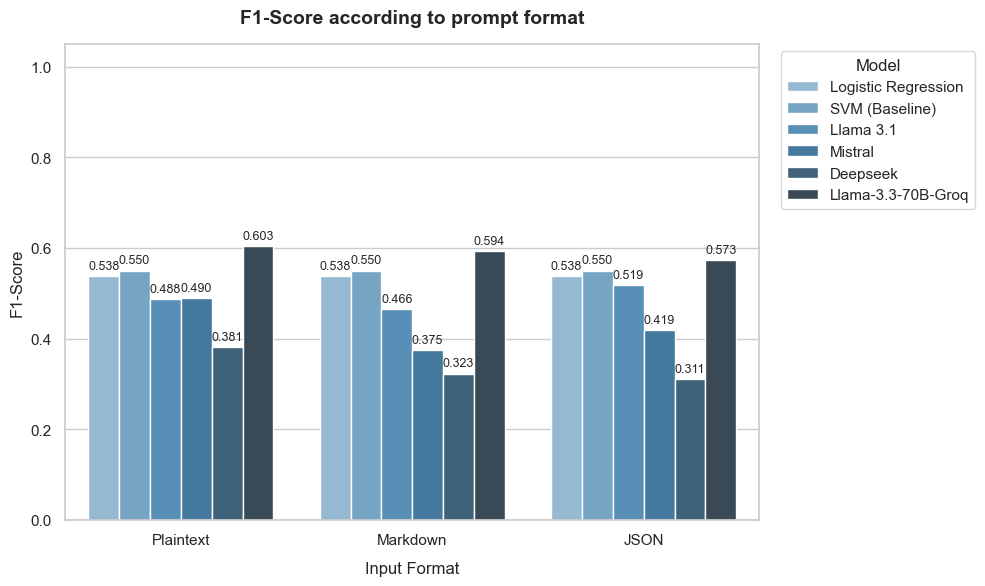

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "font.family": "sans-serif"})

plt.figure(figsize=(10, 6))

ax1 = sns.barplot(
    data=df_metrics_total,
    x="Format",
    y="F1-Score",
    hue="Model",
    palette="Blues_d",
)

plt.title("F1-Score according to prompt format", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Input Format", fontsize=12, labelpad=10)
plt.ylabel("F1-Score", fontsize=12)
plt.ylim(0, 1.05)

for p in ax1.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax1.annotate(
            f"{height:.3f}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Plot: Robustness metrics

C:\Users\Utente\AppData\Local\Temp\ipykernel_1408\3943555864.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_kappa, x="Model", y="Average_Kappa", ax=axes[0, 0], palette=llm_colors)
C:\Users\Utente\AppData\Local\Temp\ipykernel_1408\3943555864.py:11: UserWarning: 
The palette list has fewer values (3) than needed (4) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(data=df_kappa, x="Model", y="Average_Kappa", ax=axes[0, 0], palette=llm_colors)
C:\Users\Utente\AppData\Local\Temp\ipykernel_1408\3943555864.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_consistency, x="Model", y="C_Total", ax=axes[0, 1], palette=llm_colors)
C:\Users\Utente\AppDa

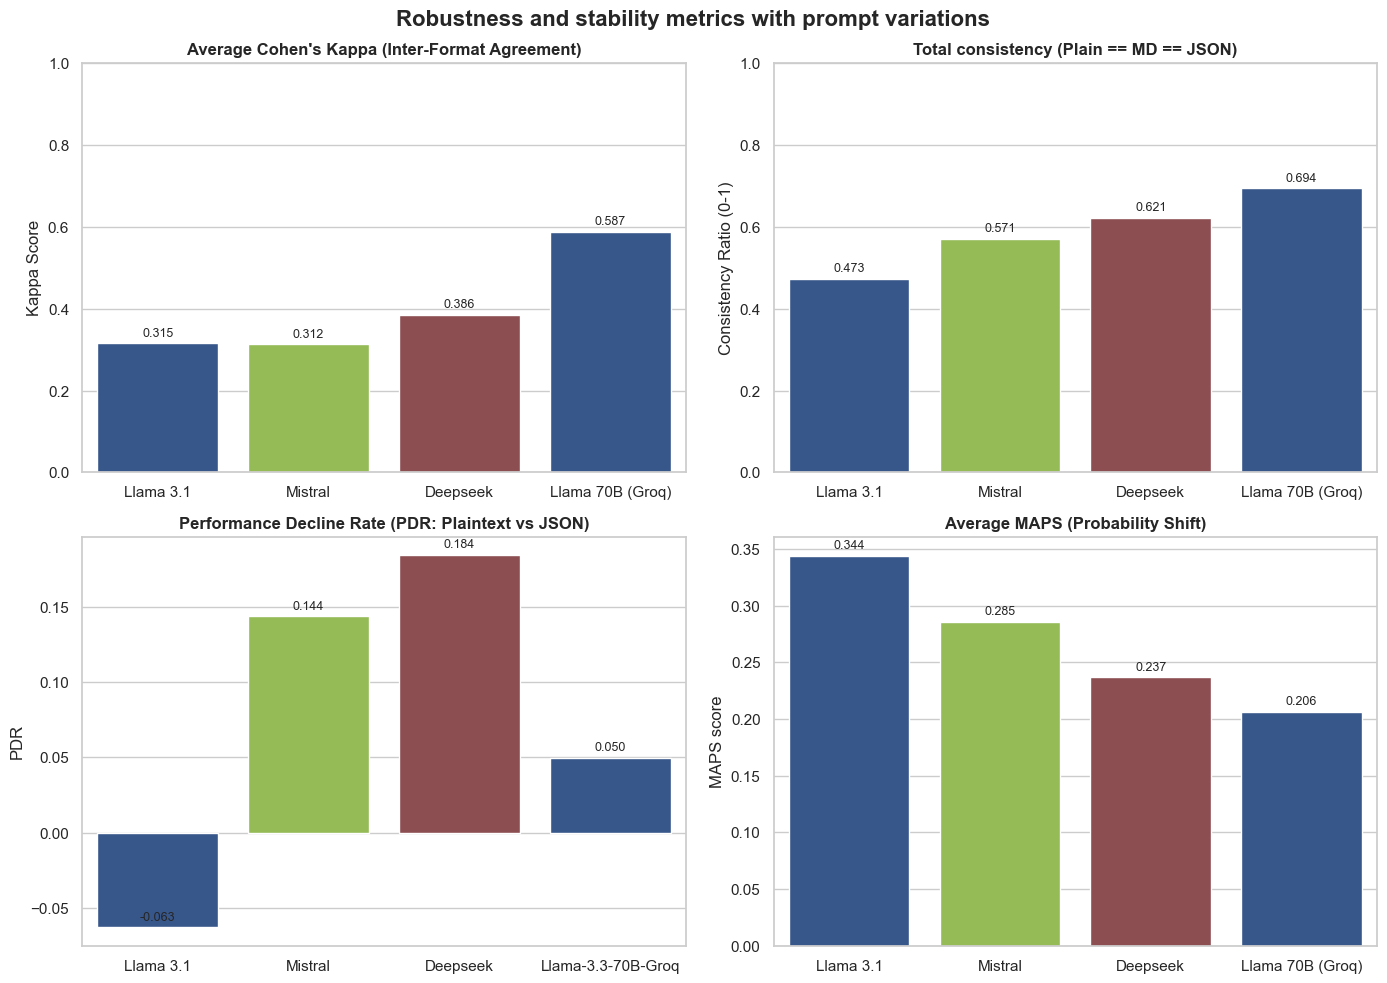

In [16]:
# JSON loss towards markdown
df_pdr_all = compute_pdr(df_metrics_llms)
df_pdr_json = df_pdr_all[df_pdr_all["Format_k"] == "JSON"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Robustness and stability metrics with prompt variations", fontsize=16, fontweight="bold", y=0.98)

llm_colors = ["#295499", "#98CC45", "#964447"]

# --- Average Cohen Kappa ---
sns.barplot(data=df_kappa, x="Model", y="Average_Kappa", ax=axes[0, 0], palette=llm_colors)
axes[0, 0].set_title("Average Cohen's Kappa (Inter-Format Agreement)", fontweight="bold")
axes[0, 0].set_ylabel("Kappa Score")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].set_xlabel("")

# --- Total consistency ---
sns.barplot(data=df_consistency, x="Model", y="C_Total", ax=axes[0, 1], palette=llm_colors)
axes[0, 1].set_title("Total consistency (Plain == MD == JSON)", fontweight="bold")
axes[0, 1].set_ylabel("Consistency Ratio (0-1)")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].set_xlabel("")

# --- PDR (Plaintext vs JSON) ---
sns.barplot(data=df_pdr_json, x="Model", y="PDR", ax=axes[1, 0], palette=llm_colors)
axes[1, 0].set_title("Performance Decline Rate (PDR: Plaintext vs JSON)", fontweight="bold")
axes[1, 0].set_ylabel("PDR")
axes[1, 0].set_xlabel("")

# --- Average MAPS ---
sns.barplot(data=df_maps, x="Model", y="Average_MAPS", ax=axes[1, 1], palette=llm_colors)
axes[1, 1].set_title("Average MAPS (Probability Shift)", fontweight="bold")
axes[1, 1].set_ylabel("MAPS score")
axes[1, 1].set_xlabel("")

for ax in axes.flat:
    for p in ax.patches:
        h = p.get_height()
        if not np.isnan(h):
            ax.annotate(
                f"{h:.3f}",
                (p.get_x() + p.get_width() / 2.0, h),
                ha="center",
                va="bottom",
                fontsize=9,
                xytext=(0, 3),
                textcoords="offset points",
            )

plt.tight_layout()
plt.show()